# Fashion-MNIST: dense vs convolutional neural networks

This notebook compares seven neural networks for classifying Fashion-MNIST clothing images
into 10 classes, built with TensorFlow/Keras:

1. **Dense networks** (no convolution): baseline vs a deeper, wider ReLU network
2. **Convolutional networks**: baseline, two-conv experiment and a final CNN with padding and dropout
3. **Optimizer settings**: the final CNN retrained with SGD and with a 10x higher Adam learning rate

Every model is trained for 10 epochs with batch size 128 and measured by test accuracy.
The last section saves the best model for the demo app.

> Runtime → Change runtime type → **T4 GPU** makes the CNNs train about 10x faster.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

keras.utils.set_random_seed(42)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data
60,000 training and 10,000 test images (28 × 28 grayscale), 6,000 / 1,000 per class.
Images get an explicit channel dimension for Conv2D, pixels are scaled to [0, 1] and labels are one-hot encoded.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28, 1) | Test: (10000, 28, 28, 1)


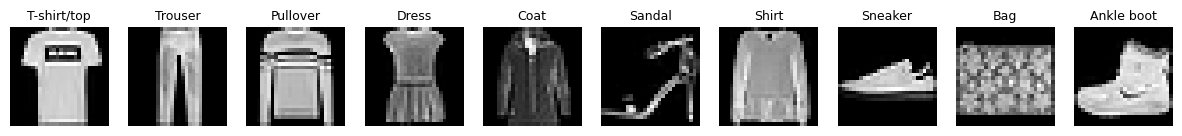

In [2]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0
y_train_oh = keras.utils.to_categorical(y_train, 10)
y_test_oh = keras.utils.to_categorical(y_test, 10)

print('Train:', x_train.shape, '| Test:', x_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c, ax in enumerate(axes):
    ax.imshow(x_train[np.where(y_train == c)[0][0]].squeeze(), cmap='gray')
    ax.set_title(class_names[c], fontsize=9)
    ax.axis('off')
plt.show()

## 2. Shared training function
Every model is compiled, trained and tested the same way, so accuracy differences come only from
the architecture or optimizer. The test set is passed as `validation_data` only to plot learning curves.

In [3]:
EPOCHS, BATCH_SIZE = 10, 128
OPTIMIZERS = {'Adam': keras.optimizers.Adam, 'SGD': keras.optimizers.SGD}
results, histories = [], {}

def train_and_test(model, group, optimizer='Adam', learning_rate=0.001):
    model.compile(optimizer=OPTIMIZERS[optimizer](learning_rate=learning_rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    model.summary()
    history = model.fit(x_train, y_train_oh, validation_data=(x_test, y_test_oh),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)
    test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
    print(f'\n{model.name} - test accuracy: {test_acc:.4f}')

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for i, metric in enumerate(['accuracy', 'loss']):
        ax[i].plot(history.history[metric], label='Training')
        ax[i].plot(history.history['val_' + metric], label='Test')
        ax[i].set_title(f'{model.name} - {metric}')
        ax[i].set_xlabel('Epoch')
        ax[i].legend()
    plt.show()

    histories[model.name] = history.history
    results[:] = [r for r in results if r['Model'] != model.name]
    results.append({'Model': model.name, 'Group': group, 'Optimizer': optimizer,
                    'Learning rate': learning_rate, 'Parameters': model.count_params(),
                    'Test accuracy': round(test_acc, 4)})
    return model

## 3. Dense networks (no convolution)
`Flatten` turns each image into 784 values. The improved model adds a hidden layer,
more neurons (64 → 256, 128) and switches sigmoid to ReLU.

Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 6s - 12ms/step - accuracy: 0.7713 - loss: 0.7671 - val_accuracy: 0.8180 - val_loss: 0.5383
Epoch 2/10
469/469 - 1s - 3ms/step - accuracy: 0.8384 - loss: 0.4683 - val_accuracy: 0.8353 - val_loss: 0.4662
Epoch 3/10
469/469 - 1s - 3ms/step - accuracy: 0.8539 - loss: 0.4165 - val_accuracy: 0.8447 - val_loss: 0.4367
Epoch 4/10
469/469 - 2s - 4ms/step - accuracy: 0.8626 - loss: 0.3885 - val_accuracy: 0.8522 - val_loss: 0.4186
Epoch 5/10
469/469 - 1s - 3ms/step - accuracy: 0.8687 - loss: 0.3690 - val_accuracy: 0.8576 - val_loss: 0.4056
Epoch 6/10
469/469 - 1s - 3ms/step - accuracy: 0.8745 - loss: 0.3539 - val_accuracy: 0.8613 - val_loss: 0.3954
Epoch 7/10
469/469 - 1s - 3ms/step - accuracy: 0.8786 - loss: 0.3414 - val_accuracy: 0.8635 - val_loss: 0.3872
Epoch 8/10
469/469 - 1s - 3ms/step - accuracy: 0.8821 - loss: 0.3308 - val_accuracy: 0.8667 - val_loss: 0.3803
Epoch 9/10
469/469 - 1s - 3ms/step - accuracy: 0.8856 - loss: 0.3216 - val_accuracy: 0.8686 - val_loss: 0.3744


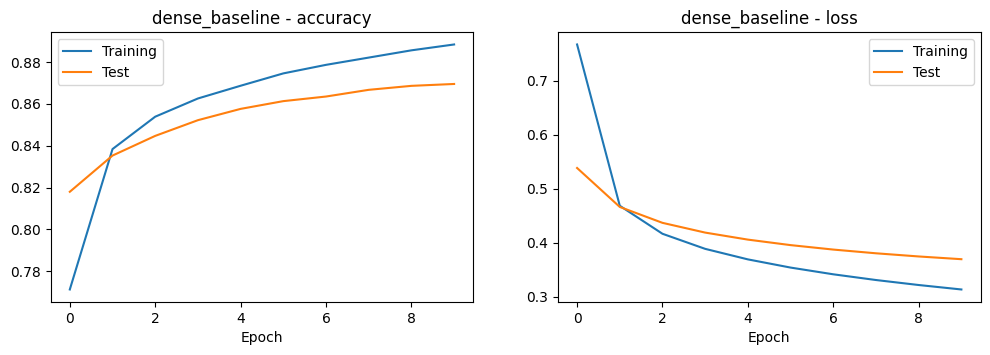

In [4]:
dense_baseline = train_and_test(keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(64, activation='sigmoid'),
    layers.Dense(10, activation='softmax'),
], name='dense_baseline'), group='Dense')

Model: "dense_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 5s - 11ms/step - accuracy: 0.8198 - loss: 0.5090 - val_accuracy: 0.8456 - val_loss: 0.4223
Epoch 2/10
469/469 - 1s - 3ms/step - accuracy: 0.8686 - loss: 0.3660 - val_accuracy: 0.8627 - val_loss: 0.3820
Epoch 3/10
469/469 - 1s - 3ms/step - accuracy: 0.8801 - loss: 0.3280 - val_accuracy: 0.8669 - val_loss: 0.3681
Epoch 4/10
469/469 - 1s - 3ms/step - accuracy: 0.8880 - loss: 0.3024 - val_accuracy: 0.8701 - val_loss: 0.3613
Epoch 5/10
469/469 - 1s - 3ms/step - accuracy: 0.8948 - loss: 0.2841 - val_accuracy: 0.8731 - val_loss: 0.3604
Epoch 6/10
469/469 - 1s - 3ms/step - accuracy: 0.9005 - loss: 0.2684 - val_accuracy: 0.8755 - val_loss: 0.3555
Epoch 7/10
469/469 - 1s - 3ms/step - accuracy: 0.9043 - loss: 0.2552 - val_accuracy: 0.8731 - val_loss: 0.3594
Epoch 8/10
469/469 - 3s - 5ms/step - accuracy: 0.9083 - loss: 0.2439 - val_accuracy: 0.8784 - val_loss: 0.3544
Epoch 9/10
469/469 - 1s - 3ms/step - accuracy: 0.9136 - loss: 0.2334 - val_accuracy: 0.8813 - val_loss: 0.3482


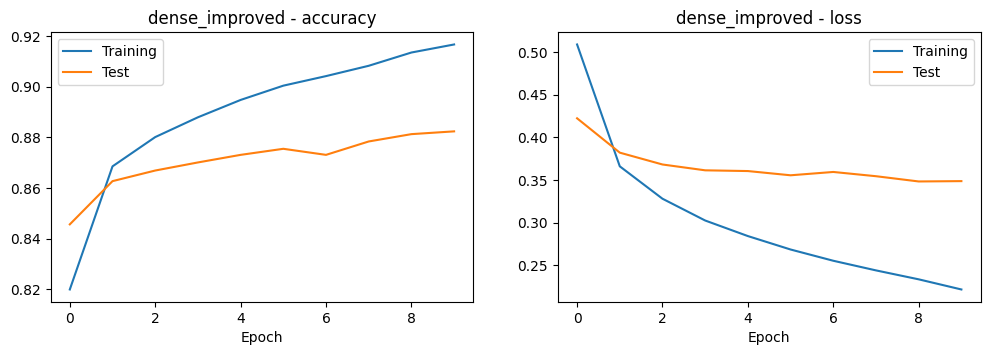

In [5]:
dense_improved = train_and_test(keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
], name='dense_improved'), group='Dense')

## 4. Convolutional networks
3 × 3 filters detect local patterns while keeping the 2D layout; 2 × 2 max pooling halves the size.
The two-conv model adds a layer without padding; the final model adds `padding='same'`,
a wider 128-neuron dense layer and dropout.

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │       173,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,930 (679.41 KB)

 Trainable params: 173,930 (679.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 8s - 16ms/step - accuracy: 0.8216 - loss: 0.5181 - val_accuracy: 0.8474 - val_loss: 0.4159
Epoch 2/10
469/469 - 2s - 4ms/step - accuracy: 0.8742 - loss: 0.3569 - val_accuracy: 0.8743 - val_loss: 0.3545
Epoch 3/10
469/469 - 2s - 4ms/step - accuracy: 0.8890 - loss: 0.3136 - val_accuracy: 0.8809 - val_loss: 0.3293
Epoch 4/10
469/469 - 2s - 4ms/step - accuracy: 0.8976 - loss: 0.2860 - val_accuracy: 0.8898 - val_loss: 0.3077
Epoch 5/10
469/469 - 2s - 4ms/step - accuracy: 0.9051 - loss: 0.2644 - val_accuracy: 0.8962 - val_loss: 0.2940
Epoch 6/10
469/469 - 2s - 3ms/step - accuracy: 0.9111 - loss: 0.2463 - val_accuracy: 0.8978 - val_loss: 0.2861
Epoch 7/10
469/469 - 2s - 3ms/step - accuracy: 0.9166 - loss: 0.2307 - val_accuracy: 0.8993 - val_loss: 0.2811
Epoch 8/10
469/469 - 2s - 4ms/step - accuracy: 0.9221 - loss: 0.2165 - val_accuracy: 0.9005 - val_loss: 0.2766
Epoch 9/10
469/469 - 2s - 3ms/step - accuracy: 0.9265 - loss: 0.2039 - val_accuracy: 0.9015 - val_loss: 0.2756


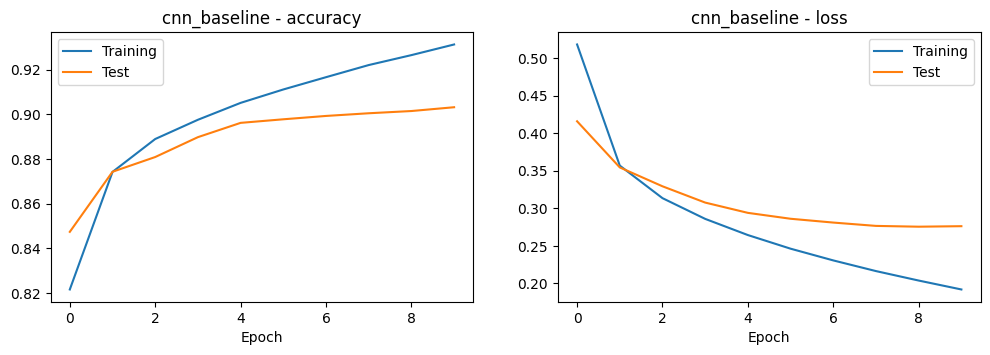

In [6]:
cnn_baseline = train_and_test(keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
], name='cnn_baseline'), group='CNN')

Model: "cnn_two_conv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 10s - 22ms/step - accuracy: 0.8012 - loss: 0.5628 - val_accuracy: 0.8543 - val_loss: 0.4045
Epoch 2/10
469/469 - 2s - 5ms/step - accuracy: 0.8701 - loss: 0.3613 - val_accuracy: 0.8648 - val_loss: 0.3764
Epoch 3/10
469/469 - 2s - 5ms/step - accuracy: 0.8856 - loss: 0.3176 - val_accuracy: 0.8720 - val_loss: 0.3595
Epoch 4/10
469/469 - 2s - 4ms/step - accuracy: 0.8959 - loss: 0.2879 - val_accuracy: 0.8791 - val_loss: 0.3355
Epoch 5/10
469/469 - 2s - 5ms/step - accuracy: 0.9040 - loss: 0.2642 - val_accuracy: 0.8875 - val_loss: 0.3152
Epoch 6/10
469/469 - 2s - 4ms/step - accuracy: 0.9106 - loss: 0.2444 - val_accuracy: 0.8950 - val_loss: 0.3001
Epoch 7/10
469/469 - 2s - 4ms/step - accuracy: 0.9162 - loss: 0.2273 - val_accuracy: 0.8974 - val_loss: 0.2904
Epoch 8/10
469/469 - 2s - 4ms/step - accuracy: 0.9219 - loss: 0.2107 - val_accuracy: 0.9005 - val_loss: 0.2847
Epoch 9/10
469/469 - 2s - 4ms/step - accuracy: 0.9283 - loss: 0.1965 - val_accuracy: 0.9010 - val_loss: 0.2813

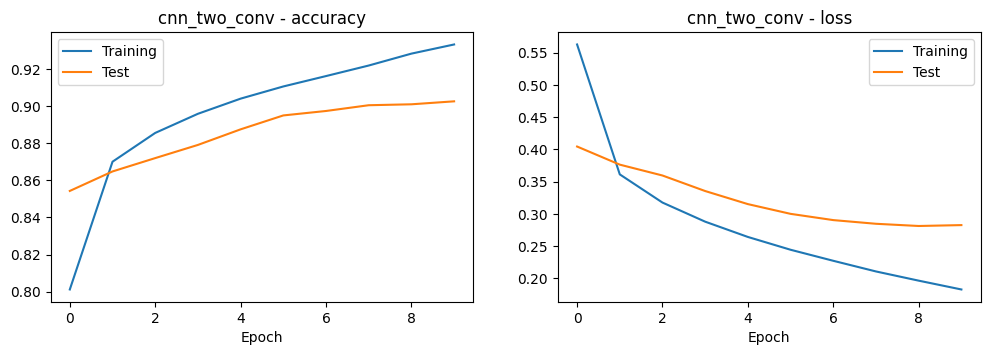

In [7]:
cnn_two_conv = train_and_test(keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
], name='cnn_two_conv'), group='CNN')

Model: "cnn_final"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 11s - 24ms/step - accuracy: 0.8087 - loss: 0.5254 - val_accuracy: 0.8679 - val_loss: 0.3597
Epoch 2/10
469/469 - 2s - 5ms/step - accuracy: 0.8798 - loss: 0.3340 - val_accuracy: 0.8763 - val_loss: 0.3288
Epoch 3/10
469/469 - 2s - 5ms/step - accuracy: 0.8955 - loss: 0.2873 - val_accuracy: 0.8866 - val_loss: 0.3113
Epoch 4/10
469/469 - 2s - 5ms/step - accuracy: 0.9058 - loss: 0.2561 - val_accuracy: 0.9008 - val_loss: 0.2738
Epoch 5/10
469/469 - 2s - 5ms/step - accuracy: 0.9151 - loss: 0.2341 - val_accuracy: 0.9014 - val_loss: 0.2675
Epoch 6/10
469/469 - 2s - 5ms/step - accuracy: 0.9212 - loss: 0.2146 - val_accuracy: 0.9033 - val_loss: 0.2671
Epoch 7/10
469/469 - 2s - 5ms/step - accuracy: 0.9277 - loss: 0.1974 - val_accuracy: 0.9000 - val_loss: 0.2757
Epoch 8/10
469/469 - 2s - 5ms/step - accuracy: 0.9331 - loss: 0.1813 - val_accuracy: 0.9087 - val_loss: 0.2482
Epoch 9/10
469/469 - 2s - 5ms/step - accuracy: 0.9373 - loss: 0.1691 - val_accuracy: 0.9149 - val_loss: 0.2321

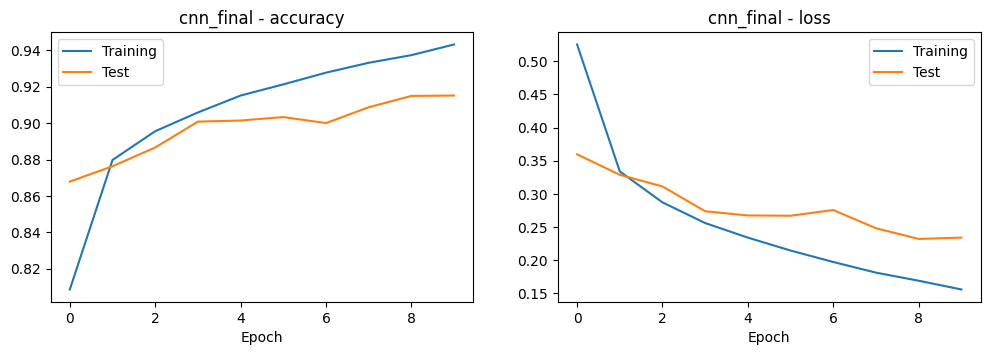

In [8]:
def build_cnn_final(name):
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax'),
    ], name=name)

cnn_final = train_and_test(build_cnn_final('cnn_final'), group='CNN')

## 5. Optimizer and learning rate
Same final CNN architecture with fresh weights; only the optimizer setting changes.

Model: "cnn_final_sgd_lr0_01"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 7s - 14ms/step - accuracy: 0.5642 - loss: 1.2390 - val_accuracy: 0.7147 - val_loss: 0.7434
Epoch 2/10
469/469 - 2s - 5ms/step - accuracy: 0.7349 - loss: 0.7187 - val_accuracy: 0.7636 - val_loss: 0.6193
Epoch 3/10
469/469 - 2s - 5ms/step - accuracy: 0.7696 - loss: 0.6276 - val_accuracy: 0.7952 - val_loss: 0.5611
Epoch 4/10
469/469 - 2s - 5ms/step - accuracy: 0.7873 - loss: 0.5770 - val_accuracy: 0.8036 - val_loss: 0.5234
Epoch 5/10
469/469 - 2s - 5ms/step - accuracy: 0.8030 - loss: 0.5429 - val_accuracy: 0.8177 - val_loss: 0.5027
Epoch 6/10
469/469 - 2s - 5ms/step - accuracy: 0.8129 - loss: 0.5139 - val_accuracy: 0.8136 - val_loss: 0.4896
Epoch 7/10
469/469 - 2s - 5ms/step - accuracy: 0.8196 - loss: 0.4934 - val_accuracy: 0.8087 - val_loss: 0.4897
Epoch 8/10
469/469 - 2s - 5ms/step - accuracy: 0.8281 - loss: 0.4764 - val_accuracy: 0.8242 - val_loss: 0.4641
Epoch 9/10
469/469 - 2s - 5ms/step - accuracy: 0.8328 - loss: 0.4598 - val_accuracy: 0.8338 - val_loss: 0.4446


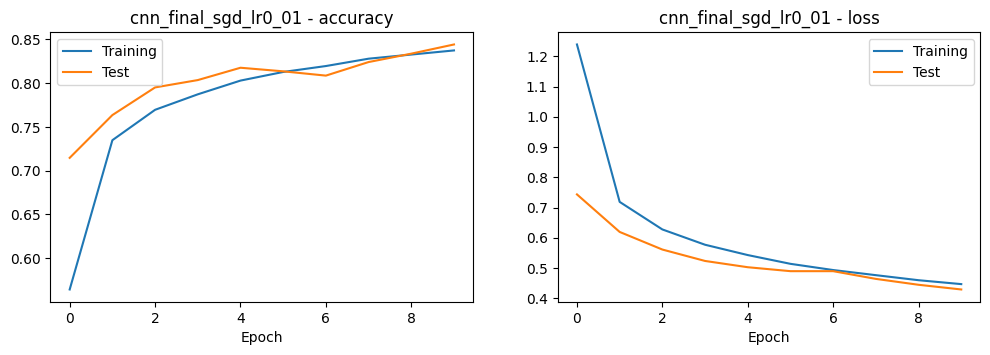

In [9]:
cnn_final_sgd = train_and_test(build_cnn_final('cnn_final_sgd_lr0_01'), group='Optimizer',
                               optimizer='SGD', learning_rate=0.01)

Model: "cnn_final_adam_lr0_01"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 8s - 17ms/step - accuracy: 0.8375 - loss: 0.4509 - val_accuracy: 0.8727 - val_loss: 0.3542
Epoch 2/10
469/469 - 2s - 5ms/step - accuracy: 0.8841 - loss: 0.3197 - val_accuracy: 0.8839 - val_loss: 0.3276
Epoch 3/10
469/469 - 2s - 5ms/step - accuracy: 0.8944 - loss: 0.2854 - val_accuracy: 0.8959 - val_loss: 0.2936
Epoch 4/10
469/469 - 2s - 5ms/step - accuracy: 0.9009 - loss: 0.2664 - val_accuracy: 0.8983 - val_loss: 0.2955
Epoch 5/10
469/469 - 2s - 5ms/step - accuracy: 0.9053 - loss: 0.2559 - val_accuracy: 0.8922 - val_loss: 0.3150
Epoch 6/10
469/469 - 2s - 5ms/step - accuracy: 0.9080 - loss: 0.2449 - val_accuracy: 0.8961 - val_loss: 0.2995
Epoch 7/10
469/469 - 2s - 5ms/step - accuracy: 0.9119 - loss: 0.2384 - val_accuracy: 0.8912 - val_loss: 0.3185
Epoch 8/10
469/469 - 2s - 5ms/step - accuracy: 0.9118 - loss: 0.2330 - val_accuracy: 0.8979 - val_loss: 0.3204
Epoch 9/10
469/469 - 2s - 5ms/step - accuracy: 0.9150 - loss: 0.2261 - val_accuracy: 0.8946 - val_loss: 0.3460


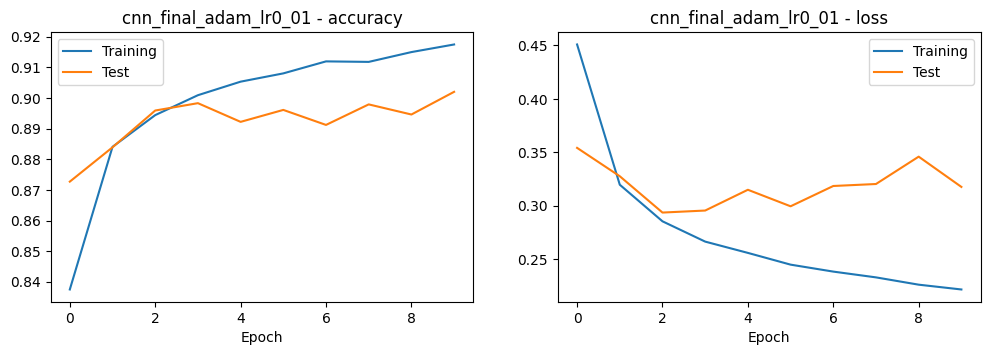

In [10]:
cnn_final_adam_high = train_and_test(build_cnn_final('cnn_final_adam_lr0_01'), group='Optimizer',
                                     optimizer='Adam', learning_rate=0.01)

## 6. Ranking

,Model,Group,Optimizer,Learning rate,Parameters,Test accuracy
Rank,,,,,,
1,cnn_final,CNN,Adam,0.001,421642,0.9151
2,cnn_baseline,CNN,Adam,0.001,173930,0.9032
3,cnn_two_conv,CNN,Adam,0.001,121930,0.9026
4,cnn_final_adam_lr0_01,Optimizer,Adam,0.010,421642,0.9020
5,dense_improved,Dense,Adam,0.001,235146,0.8824
6,dense_baseline,Dense,Adam,0.001,50890,0.8695
7,cnn_final_sgd_lr0_01,Optimizer,SGD,0.010,421642,0.8443


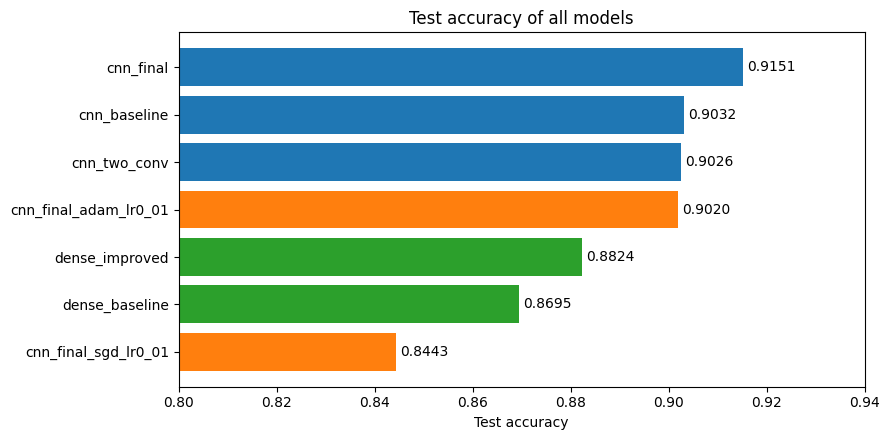

In [11]:
ranking = pd.DataFrame(results).sort_values('Test accuracy', ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = 'Rank'
display(ranking)

colours = {'Dense': 'tab:green', 'CNN': 'tab:blue', 'Optimizer': 'tab:orange'}
plt.figure(figsize=(9, 4.5))
bars = plt.barh(ranking['Model'][::-1], ranking['Test accuracy'][::-1],
                color=[colours[g] for g in ranking['Group'][::-1]])
plt.bar_label(bars, fmt='%.4f', padding=3)
plt.xlim(0.80, 0.94)
plt.xlabel('Test accuracy')
plt.title('Test accuracy of all models')
plt.tight_layout()
plt.show()

## 7. Save the best model for the demo app
Downloads `fashion_cnn.keras` (the trained final CNN) and 10 example images, one per class.
Put them in the repo's `app/` folder (model) and `app/examples/` (images).

In [12]:
cnn_final.save('fashion_cnn.keras')

os.makedirs('examples', exist_ok=True)
for c, name in enumerate(class_names):
    i = int(np.where(y_test == c)[0][0])
    fname = name.lower().replace('/', '_').replace(' ', '_')
    Image.fromarray((x_test[i].squeeze() * 255).astype('uint8')).save(f'examples/{c}_{fname}.png')

ranking.to_csv('results.csv')
!zip -qr demo_files.zip fashion_cnn.keras examples results.csv

try:
    from google.colab import files
    files.download('demo_files.zip')
except ImportError:
    print('Saved fashion_cnn.keras, examples/ and results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>